# Explore OSMa-Bench: images, questions, answers, and camera poses

Start with **Run All**. Then change the scene, search term, or frame ID in the clearly marked cells and rerun from that cell downward. This notebook reads your downloaded files; it does not download data or change the source files. The older `probe_data.ipynb` is for the previous OpenEQA setup.

You will get: a scene inventory, readable QA tables, a JSON walkthrough, RGB/depth/semantic views for the same frame, camera intrinsics and pose matrices, trajectory plots, and a player with a slider.

Select your **cleanjupyter** kernel. Required packages: `numpy pandas matplotlib Pillow PyYAML` and IPython (already present in that kernel when this notebook was created). If another kernel lacks them, install with `%pip install numpy pandas matplotlib Pillow PyYAML` in that kernel, then restart it.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (here, *here.parents)
                     if (p / 'code' / 'download_dependencies.ipynb').exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the project root or code folder.')
sys.path.insert(0, str(PROJECT_ROOT / 'code'))
from osma_explorer import (inventory, load_scene, frame_id, frame_data,
                           show_frame, plot_trajectory, animate_scene, camera_to_world)
DATA_ROOT = PROJECT_ROOT / 'dataset' / 'osma-bench' / 'data'
pd.set_option('display.max_colwidth', 140)
print('Reading:', DATA_ROOT)


Reading: D:\School Stuff\shanghai work\Senior Capstone\dataset\osma-bench\data


## 1. What is inside this download?

The hierarchy is **dataset family ? scene ? observations and metadata**. One scene is an indoor environment. A frame is one camera observation of that scene. Questions exist for selected frames, not for every image.

| File inside a scene | What it contains |
|---|---|
| `results/frame000097.jpg` | RGB image for frame 97 |
| `results/depth000097.png` | Encoded depth for the same frame |
| `results/semantic000097.png` | One semantic class ID per pixel |
| `traj.txt` | One flattened 4?4 pose per frame, row 0 for frame 0 |
| `camera_params.yaml` | Image size, focal lengths, principal point, and depth scale |
| `embed_semseg_classes.json` | Mapping from semantic class IDs to names for this scene |
| `vqa/<scene>_questions.json` | Generated question?answer candidates |
| `vqa/<scene>_validated_questions.json` | QA retained by the dataset's validation process |
| `vqa/<scene>_descriptions.json` | Descriptions and camera fields attached to sampled frames |

The inventory measures the files actually present. It does not assume every lighting configuration described in the paper is packaged as a separate sequence here. ?Validated? is the publisher's designation, not a guarantee that every answer is correct.

In [2]:
scene_paths, scene_summary, all_qa = inventory(DATA_ROOT)
columns = ['family', 'scene', 'rgb', 'depth', 'semantic', 'poses', 'qa_frames', 'generated_qa', 'validated_qa']
display(scene_summary[columns])
print(f"{len(scene_summary):,} scenes | {scene_summary.rgb.sum():,} RGB frames | {len(all_qa):,} validated QA pairs")
display(scene_summary.groupby('family')[['rgb', 'poses', 'validated_qa']].sum())


,family,scene,rgb,depth,semantic,poses,qa_frames,generated_qa,validated_qa
0,hm3d,00800-TEEsavR23oF,756,756,756,756,8,154,81
1,hm3d,00802-wcojb4TFT35,318,318,318,318,5,107,74
2,hm3d,00803-k1cupFYWXJ6,420,420,420,420,4,79,57
3,hm3d,00808-y9hTuugGdiq,1234,1234,1234,1234,8,169,132
4,hm3d,00810-CrMo8WxCyVb,1504,1504,1504,1504,11,261,119
5,hm3d,00813-svBbv1Pavdk,810,810,810,810,9,230,137
6,hm3d,00814-p53SfW6mjZe,436,436,436,436,5,122,39
7,hm3d,00815-h1zeeAwLh9Z,442,442,442,442,3,62,42
8,replica_cad,apt_0,1636,1636,1636,1636,15,322,205
9,replica_cad,apt_3,1502,1502,1502,1502,16,347,222


30 scenes | 30,376 RGB frames | 4,736 validated QA pairs


,rgb,poses,validated_qa
family,,,
hm3d,5920,5920,681
replica_cad,24456,24456,4055


## 2. Select a scene

Change `FAMILY` and `SCENE_NAME` using the table above, then rerun this cell and the cells below. The notebook initially opens the first HM3D scene.

In [3]:
FAMILY = 'hm3d'  # 'hm3d' or 'replica_cad'
SCENE_NAME = '00800-TEEsavR23oF'  # for example: 'apt_0' with FAMILY='replica_cad'
scene_path = DATA_ROOT / FAMILY / SCENE_NAME
if scene_path not in scene_paths:
    raise ValueError('Choose a family/scene pair from the inventory table.')
scene = load_scene(scene_path)
qa = scene['qa']
print('Selected:', scene_path)
print('RGB frame IDs:', min(scene['rgb']), 'through', max(scene['rgb']))
print('Frames with validated questions:', sorted(qa.frame_id.unique().tolist()))
print('Categories:', sorted(qa.category.unique().tolist()))


Selected: D:\School Stuff\shanghai work\Senior Capstone\dataset\osma-bench\data\hm3d\00800-TEEsavR23oF
RGB frame IDs: 0 through 755
Frames with validated questions: [0, 97, 194, 291, 388, 485, 582, 679]
Categories: ['Binary Existence-Based', 'Binary General', 'Binary Logical', 'Comparison', 'Measurement', 'Object Attributes', 'Object Relations - Spatial']


## 3. How to read the question JSON

JSON objects (`{...}`) become Python dictionaries; JSON arrays (`[...]`) become Python lists. The file is not one flat list of questions:

```text
scene_name
parameters                         list of sampled frames
  [0].frame                        image filename
  [0].qa                           list of QA records for that frame
    [0].question                   question text
    [0].answer                     supplied reference answer
    [0].category                   question type
```

For example, `raw['parameters'][0]['qa'][0]['answer']` means: first sampled frame ? first QA pair ? its answer. `[0]` means the first list item. The following cell loads the real JSON and prints a small example. **A list index is not necessarily a frame ID**: the second sampled frame can be frame 97, not frame 1.

In [4]:
QA_PATH = scene_path / 'vqa' / f'{SCENE_NAME}_validated_questions.json'
with QA_PATH.open(encoding='utf-8') as handle:
    raw = json.load(handle)
print('Top-level keys:', list(raw))
print('Scene:', raw['scene_name'])
print('Number of sampled frame records:', len(raw['parameters']))
example = next((item for item in raw['parameters'] if item.get('qa')), None)
if example is not None:
    print(json.dumps({'frame': example['frame'], 'qa': example['qa'][:1]}, indent=2, ensure_ascii=False))
    print('Answer in that example:', example['qa'][0]['answer'])
else:
    print('This file contains no QA pairs.')

# Flatten the nesting: ONE row per question, keeping its frame as a join key.
rows = [dict(frame=item['frame'], **pair)
        for item in raw['parameters'] for pair in item['qa']]
readable_qa = pd.DataFrame(rows)
display(readable_qa.head(10))


Top-level keys: ['scene_name', 'parameters']
Scene: 00800-TEEsavR23oF
Number of sampled frame records: 8
{
  "frame": "frame000000.jpg",
  "qa": [
    {
      "question": "Is the headboard made of metal?",
      "answer": "No",
      "category": "Binary General"
    }
  ]
}
Answer in that example: No


,frame,question,answer,category
0,frame000000.jpg,Is the headboard made of metal?,No,Binary General
1,frame000000.jpg,Is there a rug on the floor?,No,Binary General
2,frame000000.jpg,Is the tissue box green?,No,Binary General
3,frame000000.jpg,Is there pillows AND a chair?,No,Binary Logical
4,frame000000.jpg,What color are the pillows with stripes?,Gray and white,Object Attributes
5,frame000000.jpg,What color is the lampshade on the table?,Beige,Object Attributes
6,frame000000.jpg,What is positioned behind the pillows?,Wooden framed headboard,Object Relations - Spatial
7,frame000000.jpg,What is on the table?,"Beige lampshade lamp, Blue tissues box",Object Relations - Spatial
8,frame000000.jpg,How many lamps are present?,1,Measurement
9,frame000000.jpg,Which is positioned higher: the lamp or the drawer table?,The lamp,Comparison


## 4. Search questions and compare categories

Edit `KEYWORD`, `CATEGORY`, and `SEARCH_ALL_SCENES`. Empty keyword and `CATEGORY = None` show all questions. Search checks both question and answer text, using literal text rather than regular expressions. `OFFSET` pages through the results. Keep the scene/frame columns when exporting or comparing questions: they identify the relevant observation.

81 matching questions; showing rows 0 through 19.


,family,scene,frame,category,question,answer
0,hm3d,00800-TEEsavR23oF,frame000000.jpg,Binary General,Is the headboard made of metal?,No
1,hm3d,00800-TEEsavR23oF,frame000000.jpg,Binary General,Is there a rug on the floor?,No
2,hm3d,00800-TEEsavR23oF,frame000000.jpg,Binary General,Is the tissue box green?,No
3,hm3d,00800-TEEsavR23oF,frame000000.jpg,Binary Logical,Is there pillows AND a chair?,No
4,hm3d,00800-TEEsavR23oF,frame000000.jpg,Object Attributes,What color are the pillows with stripes?,Gray and white
5,hm3d,00800-TEEsavR23oF,frame000000.jpg,Object Attributes,What color is the lampshade on the table?,Beige
6,hm3d,00800-TEEsavR23oF,frame000000.jpg,Object Relations - Spatial,What is positioned behind the pillows?,Wooden framed headboard
7,hm3d,00800-TEEsavR23oF,frame000000.jpg,Object Relations - Spatial,What is on the table?,"Beige lampshade lamp, Blue tissues box"
8,hm3d,00800-TEEsavR23oF,frame000000.jpg,Measurement,How many lamps are present?,1
9,hm3d,00800-TEEsavR23oF,frame000000.jpg,Comparison,Which is positioned higher: the lamp or the drawer table?,The lamp


,questions
category,
Binary General,17
Object Relations - Spatial,16
Object Attributes,14
Binary Logical,11
Comparison,11
Binary Existence-Based,9
Measurement,3


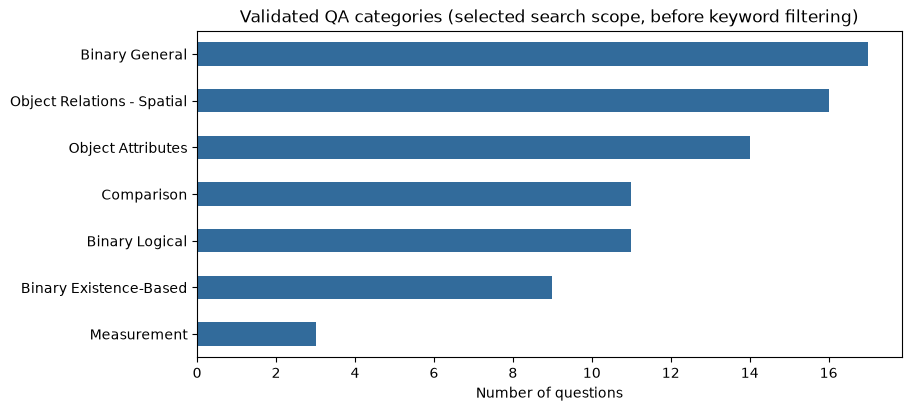

In [5]:
SEARCH_ALL_SCENES = False
KEYWORD = ''  # for example 'chair' or 'blue'
CATEGORY = None  # for example 'Object Attributes'
OFFSET = 0
PAGE_SIZE = 20
questions = all_qa if SEARCH_ALL_SCENES else qa
filtered_qa = questions.copy()
if KEYWORD:
    mask = (filtered_qa.question.str.contains(KEYWORD, case=False, regex=False, na=False)
            | filtered_qa.answer.astype(str).str.contains(KEYWORD, case=False, regex=False, na=False))
    filtered_qa = filtered_qa[mask]
if CATEGORY is not None:
    filtered_qa = filtered_qa[filtered_qa.category == CATEGORY]
print(f'{len(filtered_qa):,} matching questions; showing rows {OFFSET} through {OFFSET + PAGE_SIZE - 1}.')
with pd.option_context('display.max_colwidth', None):
    display(filtered_qa[['family', 'scene', 'frame', 'category', 'question', 'answer']].iloc[OFFSET:OFFSET + PAGE_SIZE])

category_counts = questions.category.value_counts().rename('questions').to_frame()
display(category_counts)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
category_counts.sort_values('questions').plot.barh(ax=ax, legend=False, color='#326b9b')
ax.set(title='Validated QA categories (selected search scope, before keyword filtering)', xlabel='Number of questions', ylabel='')
display(fig)
plt.close(fig)


## 5. Inspect one frame: RGB, depth, semantic labels, and its QA

Set `FRAME_ID` to a number from this scene. RGB/depth/semantic files and trajectory rows are matched by the numeric frame ID, never by a filtered table row number. If you searched all scenes, select that question's family and scene in section 2 before choosing its frame.

Depth PNGs store integers. Convert using `depth_metres = raw_pixel / png_depth_scale` from the scene's YAML. Raw zero is displayed as missing depth. Semantic pixel values are **category IDs**, not distances, confidence scores, or counts of individual objects. Use this scene's class mapping; class IDs can differ between families.

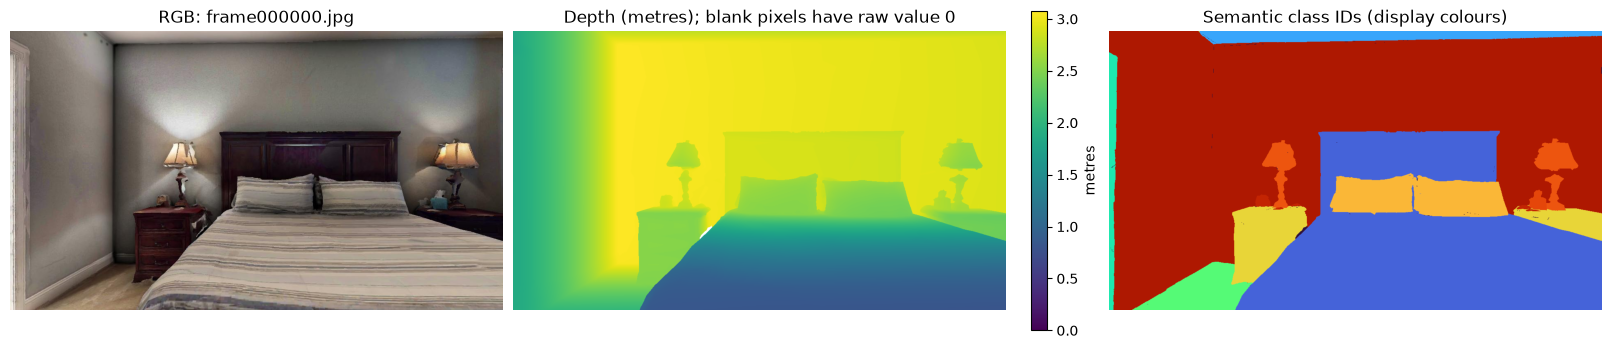

Semantic classes visible in this frame (percent means image area, not object count):


,class_id,class_name,pixels,percent_of_image
12,121,wall,448763,55.00
2,15,bed,231933,28.42
8,87,pillow,35100,4.30
7,80,nightstand,33032,4.05
3,28,ceiling,21435,2.63
5,54,floor,18924,2.32
9,105,table lamp,13820,1.69
4,45,door frame,9488,1.16
11,117,unknown,1526,0.19
10,108,tissue box,1489,0.18


Validated questions for frame 0: 10


,category,question,answer
0,Binary General,Is the headboard made of metal?,No
1,Binary General,Is there a rug on the floor?,No
2,Binary General,Is the tissue box green?,No
3,Binary Logical,Is there pillows AND a chair?,No
4,Object Attributes,What color are the pillows with stripes?,Gray and white
5,Object Attributes,What color is the lampshade on the table?,Beige
6,Object Relations - Spatial,What is positioned behind the pillows?,Wooden framed headboard
7,Object Relations - Spatial,What is on the table?,"Beige lampshade lamp, Blue tissues box"
8,Measurement,How many lamps are present?,1
9,Comparison,Which is positioned higher: the lamp or the drawer table?,The lamp


Supplied description:
- Wooden framed headboard is behind pillows.
- Gray and white striped pillows are on the bed.
- Striped bed cover is on the bed.
- Beige lampshade lamp is on the table.
- Blue tissues box is on the table.
- Brown wooden drawer table is next to the bed.


In [6]:
FRAME_ID = 0  # try 97 in the default HM3D scene
fig, visible_classes = show_frame(scene, FRAME_ID)
display(fig)
plt.close(fig)
print('Semantic classes visible in this frame (percent means image area, not object count):')
display(visible_classes)
frame_qa = qa[qa.frame_id == FRAME_ID]
print(f'Validated questions for frame {FRAME_ID}: {len(frame_qa)}')
with pd.option_context('display.max_colwidth', None):
    display(frame_qa[['category', 'question', 'answer']])
if frame_qa.empty:
    print('This frame has no validated QA; that does not mean its image is missing.')
for item in scene['descriptions']:
    if frame_id(item['frame']) == FRAME_ID:
        print('Supplied description:')
        print(item.get('description', '<none>'))


## 6. Understand the camera parameters and pose matrix

**Intrinsics** describe how the camera projects 3D points onto image pixels: `fx, fy` are focal lengths in pixels and `cx, cy` locate the image center used by the projection. They form the 3?3 matrix `K` below.

**Pose** describes location and orientation. Each `traj.txt` row contains 16 numbers; reshape them in row-major order into a 4?4 matrix. Under a camera-to-world convention, the upper-left 3?3 block is rotation `R`, the upper-right column is position `t`, and `p_world = R @ p_camera + t`. The last row should be `[0, 0, 0, 1]`.

The plots below explicitly assume **camera-to-world** and **+Z camera forward**. Matrix validity alone cannot prove a coordinate convention; these are adjustable interpretation settings, not something inferred from array shape. Use `POSE_CONVENTION = 'world_to_camera'` to invert matrices if the exporter requires it. Use `FORWARD_SIGN = -1` for a -Z forward convention. X-Z is a coordinate projection; no timestamps are available here to infer camera speed.

Use `traj.txt` for this inspection. Some camera fields in the supplied descriptions do not equal the corresponding trajectory values. The comparison below exposes that difference instead of silently using those fields as poses.

Camera metadata:


,value
crop_edge,0.0
cx,599.5
cy,339.5
fx,600.0
fy,600.0
image_height,680.0
image_width,1200.0
png_depth_scale,6553.5


Intrinsic matrix K:


,0,1,2
0,600.0,0.0,599.5
1,0.0,600.0,339.5
2,0.0,0.0,1.0


traj.txt row 0, reshaped to 4 x 4:


,column 0,column 1,column 2,translation
0,0.999391,-0.0,-0.034899,1.231068
1,0.000000,-1.0,-0.000000,1.163378
2,-0.034899,-0.0,-0.999391,-5.688394
3,0.000000,0.0,0.000000,1.000000


Camera position under the selected convention: [ 1.2310679   1.163378   -5.68839359]
Rotation determinant (expect about +1): 0.9999999999999999
Rotation orthogonality error (expect about 0): 1.1102230246251565e-16
Description JSON camera fields (shown as supplied, not used as poses):
{
  "position": [
    1.2310678958892822,
    0.0,
    -1.0
  ],
  "orientation": [
    0.9993908270842111,
    -0.0,
    -0.03489949483783874,
    -0.0,
    1.1633780002593994,
    -0.03489949483783874,
    -0.0,
    -0.9993908270842111,
    -5.688393592834473
  ]
}


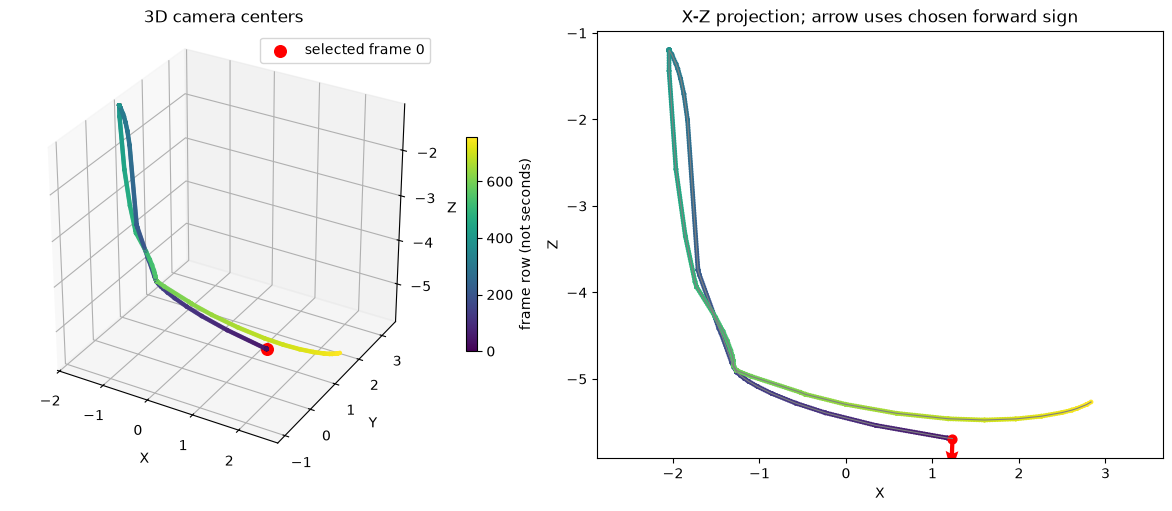

In [7]:
POSE_CONVENTION = 'camera_to_world'
FORWARD_SIGN = 1
params = scene['camera']
K = np.array([[params['fx'], 0, params['cx']],
              [0, params['fy'], params['cy']], [0, 0, 1]], dtype=float)
print('Camera metadata:')
display(pd.Series(params, name='value').to_frame())
print('Intrinsic matrix K:')
display(pd.DataFrame(K))
raw_pose = scene['poses'][FRAME_ID]
print(f'traj.txt row {FRAME_ID}, reshaped to 4 x 4:')
display(pd.DataFrame(raw_pose, columns=['column 0', 'column 1', 'column 2', 'translation']))
pose = camera_to_world(scene['poses'], POSE_CONVENTION)[FRAME_ID]
print('Camera position under the selected convention:', pose[:3, 3])
print('Rotation determinant (expect about +1):', np.linalg.det(pose[:3, :3]))
print('Rotation orthogonality error (expect about 0):', np.max(np.abs(pose[:3, :3].T @ pose[:3, :3] - np.eye(3))))
for item in scene['descriptions']:
    if frame_id(item['frame']) == FRAME_ID:
        print('Description JSON camera fields (shown as supplied, not used as poses):')
        print(json.dumps(item.get('camera', {}), indent=2))
fig = plot_trajectory(scene, FRAME_ID, POSE_CONVENTION, FORWARD_SIGN)
display(fig)
plt.close(fig)


## 7. Play a sampled camera walkthrough

The player below has play/pause and a slider, and moves a red dot along the trajectory alongside each RGB view. It uses a bounded, evenly spaced sample to keep notebook output small. Playback timing is for viewing, not the original capture speed. No widget extension or video encoder is needed. If HTML playback is unavailable in your viewer, section 5 works by editing `FRAME_ID`.

In [8]:
MAKE_PLAYER = True
MAX_PLAYER_FRAMES = 24  # increase moderately for a smoother view
if MAKE_PLAYER:
    display(HTML(animate_scene(scene, max_frames=MAX_PLAYER_FRAMES, convention=POSE_CONVENTION)))


## 8. Check alignment and data quality before using the data

Zero is the expected result for missing files, ID differences, non-finite poses, bad homogeneous last rows, and invalid rotations. Rotation checks measure orthogonality and determinant. They do not establish camera-to-world vs world-to-camera. The description-position count compares supplied JSON positions to the trajectory translation column; it flags discrepancies without rewriting the data.

The checks scan metadata and filenames for every scene, and load images for the selected frame. They are not an exhaustive visual review of every frame or every supplied answer. For a research train/test split, split by **scene**, not randomly by question: questions from nearby frames can describe the same objects.

In [9]:
audit_columns = ['qa_frames_missing_rgb', 'rgb_depth_id_differences',
                 'rgb_semantic_id_differences', 'rgb_pose_id_differences',
                 'nonfinite_poses', 'invalid_last_rows', 'invalid_rotations',
                 'description_position_disagreements']
display(scene_summary[['family', 'scene'] + audit_columns])
print('Totals across scenes:')
display(scene_summary[audit_columns].sum().rename('count').to_frame())
print('Identical repeated validated QA records (same family/scene/frame/question/answer/category):',
      int(all_qa.duplicated(['family', 'scene', 'frame', 'question', 'answer', 'category']).sum()))
print('Generated QA:', int(scene_summary.generated_qa.sum()), '| Validated QA:', len(all_qa))


,family,scene,qa_frames_missing_rgb,rgb_depth_id_differences,rgb_semantic_id_differences,rgb_pose_id_differences,nonfinite_poses,invalid_last_rows,invalid_rotations,description_position_disagreements
0,hm3d,00800-TEEsavR23oF,0,0,0,0,0,0,0,8
1,hm3d,00802-wcojb4TFT35,0,0,0,0,0,0,0,5
2,hm3d,00803-k1cupFYWXJ6,0,0,0,0,0,0,0,4
3,hm3d,00808-y9hTuugGdiq,0,0,0,0,0,0,0,8
4,hm3d,00810-CrMo8WxCyVb,0,0,0,0,0,0,0,11
5,hm3d,00813-svBbv1Pavdk,0,0,0,0,0,0,0,9
6,hm3d,00814-p53SfW6mjZe,0,0,0,0,0,0,0,5
7,hm3d,00815-h1zeeAwLh9Z,0,0,0,0,0,0,0,3
8,replica_cad,apt_0,0,0,0,0,0,0,0,15
9,replica_cad,apt_3,0,0,0,0,0,0,0,16


Totals across scenes:


,count
qa_frames_missing_rgb,0
rgb_depth_id_differences,0
rgb_semantic_id_differences,0
rgb_pose_id_differences,0
nonfinite_poses,0
invalid_last_rows,0
invalid_rotations,0
description_position_disagreements,347


Identical repeated validated QA records (same family/scene/frame/question/answer/category): 0
Generated QA: 7394 | Validated QA: 4736


## 9. Optional: export readable tables

Set `EXPORT_TABLES = True` to create CSVs you can open in Excel. The export includes source file paths and frame IDs. It writes only derived tables under `dataset/_analysis/osma-bench/`; it does not alter any original JSON, images, or poses.

In [10]:
EXPORT_TABLES = False
if EXPORT_TABLES:
    export_root = PROJECT_ROOT / 'dataset' / '_analysis' / 'osma-bench'
    export_root.mkdir(parents=True, exist_ok=True)
    all_qa.to_csv(export_root / 'validated_questions.csv', index=False, encoding='utf-8-sig')
    scene_summary.to_csv(export_root / 'scene_inventory.csv', index=False, encoding='utf-8-sig')
    print('Saved tables to:', export_root)
else:
    print('CSV export disabled; set EXPORT_TABLES = True to save tables.')


CSV export disabled; set EXPORT_TABLES = True to save tables.
